# 8주차 분석 (CPU) — 딥러닝 4종 채점 · 순위표 · 누적 비교표

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau, wilcoxon

ROOT = Path("..").resolve()
sys.path.append(str(ROOT))
from src.metrics import compute_naive_denominators, score_backtest
from src import bench_models as bm, tslib_adapter as ta

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

OUT = ROOT / "results/wk8"
PRED_DIR = OUT / "preds"
env = json.load(open(OUT / "env.json", encoding="utf-8"))
SEED, ONCE, REFIT = env["seed"], 10**6, 1344
MODELS = ta.MODELS
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#8e5bd0"]))  # 모델별 고정 색 (모든 그래프 공통)

data = bm.load_data()
runs = pd.read_csv(OUT / "run_log.csv").drop_duplicates("run", keep="last").set_index("run")
fits = pd.read_csv(OUT / "fit_log.csv").drop_duplicates(["run", "학습 끝 시점"], keep="last")
wk6 = pd.read_csv(ROOT / "results/wk6/mase_summary.csv", index_col=0)
NAIVE = {24: wk6.loc["Seasonal Naive", "MASE(24h)"], 168: wk6.loc["Seasonal Naive", "MASE(168h)"]}

def vs_naive(x, h):
    return (x / NAIVE[h] - 1) * 100  # 음수 = 개선

def mase_by_building(res):
    denom = compute_naive_denominators(data, train_end=data.index.get_loc(res["timestamp"].min()), season=168)
    return score_backtest(res, denom)[0].set_index("building")["MASE"]

preds = {r: pd.read_parquet(PRED_DIR / f"{r}.parquet") for r in runs.index}
pb = pd.DataFrame({r: mase_by_building(p) for r, p in preds.items()}).T  # (실행 × 건물)
runs["MASE"] = pb.mean(axis=1)
assert np.allclose(runs["MASE"], runs["MASE_평균"]), "서버 채점과 불일치"

def pick(**kw):
    # 조건에 맞는 실행 (모델당 1개) → model 인덱스, run 은 열로. 기본 = M · expanding · 1회 학습 · seed 2021
    q = runs
    for k, v in {"mode": "M", "train_mode": "expanding", "refit_hours": ONCE, "seed": SEED, **kw}.items():
        q = q[q[k] == v]
    return q.reset_index().set_index("model")

print(f"실행 {len(runs)}개 | GPU {env['gpu']} | TSLib {env['tslib_commit']}")
print(runs.groupby(["task", "refit_hours"]).size().rename("실행 수").to_string())
print(f"Seasonal Naive MASE: 24h {NAIVE[24]:.4f} / 168h {NAIVE[168]:.4f}")

실행 36개 | GPU NVIDIA GB10 | TSLib 4e938a1
task      refit_hours
8-2/8-3a  1000000        12
8-3b      1344            8
8-4       1000000         4
8-5       1000000         4
seed      1000000         8
Seasonal Naive MASE: 24h 0.9673 / 168h 0.9767


## 과제 8-2. 4종 동일 조건 비교 — 성능 + 학습시간 + VRAM (look-back 336 · 168h · 1회 학습)

측정 조건: GPU NVIDIA GB10 · batch 32 · 에폭 상한 10 · patience 3 · seed 2021 · 1회 학습 (학습 행 8808)
              MASE(168h)  Naive 대비(%)  학습 1회(s)  실행 에폭  최대 VRAM(GB)    파라미터 수  추론 ms/창  DLinear 대비 학습시간(배)
model                                                                                                     
DLinear           1.0429       6.7783    4.2554   10.0       0.1019    113232   0.4823              1.0000
PatchTST          0.8901      -8.8726  336.6983    7.0       4.5616   9926824   1.8831             79.1235
iTransformer      0.9150      -6.3171   11.9400    4.0       0.2310   4993704   6.4779              2.8059
TimeXer           0.9510      -2.6307  225.5506    4.0       4.1793  14695080   2.3958             53.0040

참고 — 6주차 LightGBM 학습 1회 (노트북 CPU): {'LightGBM (local)': 4.29, 'LightGBM (global)': 5.97}


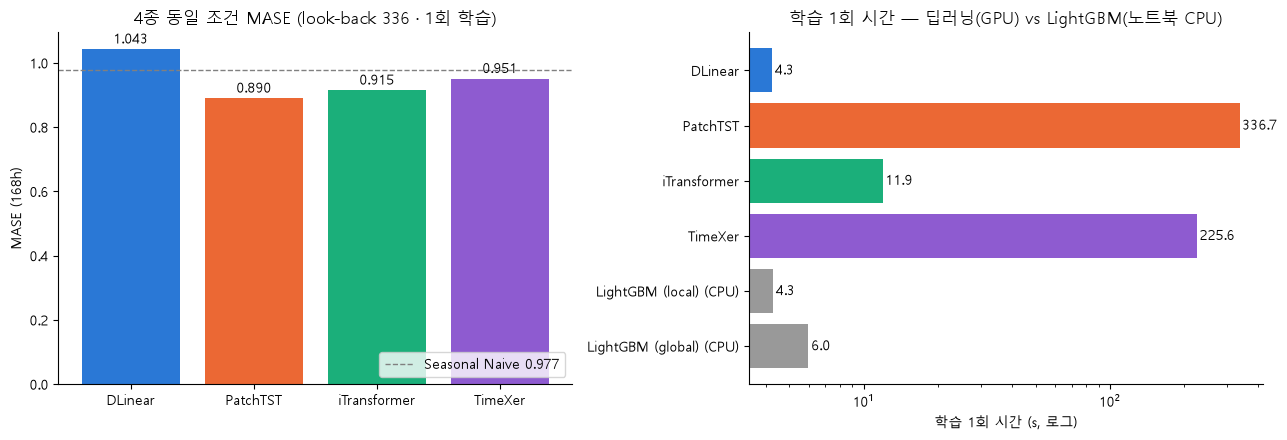

In [2]:
base = pick(seq_len=336, horizon=168).reindex(MODELS)
same = pd.DataFrame({
    "MASE(168h)": base["MASE"], "Naive 대비(%)": vs_naive(base["MASE"], 168),
    "학습 1회(s)": base["학습 1회 평균(s)"], "실행 에폭": base["평균 실행 에폭"],
    "최대 VRAM(GB)": base["최대 VRAM(GB)"], "파라미터 수": base["파라미터 수"],
    "추론 ms/창": base["추론 시간 합(s)"] / 52 * 1000})
same["DLinear 대비 학습시간(배)"] = same["학습 1회(s)"] / same.loc["DLinear", "학습 1회(s)"]
same.to_csv(OUT / "same_condition_table.csv", encoding="utf-8")
print(f"측정 조건: GPU {env['gpu']} · batch {env['train']['batch_size']} · 에폭 상한 {env['train']['train_epochs']} · "
      f"patience {env['train']['patience']} · seed {SEED} · 1회 학습 (학습 행 {fits.loc[fits['run'] == base.loc['DLinear', 'run'], '학습 행 수'].item()})")
print(same.round(4).to_string())

bench6 = pd.read_csv(ROOT / "results/wk6/benchmark_table.csv", index_col=0)
lgb_fit = bench6["학습 시간(s)"].dropna()  # 6주차: 노트북 CPU 4스레드, 학습 1회
print()
print("참고 — 6주차 LightGBM 학습 1회 (노트북 CPU):", lgb_fit.round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
bars = ax.bar(MODELS, same["MASE(168h)"], color=[COLORS[m] for m in MODELS])
ax.bar_label(bars, fmt="%.3f", padding=2)
ax.axhline(NAIVE[168], color="gray", ls="--", lw=1, label=f"Seasonal Naive {NAIVE[168]:.3f}")
ax.set_ylabel("MASE (168h)")
ax.set_title("4종 동일 조건 MASE (look-back 336 · 1회 학습)")
ax.legend(loc="lower right")
ax = axes[1]
t = pd.concat([same["학습 1회(s)"], lgb_fit.rename(lambda s: s + " (CPU)")])
bars = ax.barh(t.index, t, color=[COLORS.get(m, "#999999") for m in t.index])
ax.bar_label(bars, fmt="%.1f", padding=2)
ax.set_xscale("log")
ax.invert_yaxis()
ax.set_xlabel("학습 1회 시간 (s, 로그)")
ax.set_title("학습 1회 시간 — 딥러닝(GPU) vs LightGBM(노트북 CPU)")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "same_condition.png", dpi=110)
plt.show()

## 과제 8-3a. 모델 층 — look-back 96 / 336 / 512 순위표 (168h · 1회 학습)

model      DLinear  PatchTST  iTransformer  TimeXer
look-back                                          
96          1.2292    0.9663        0.9131   0.9203
336         1.0429    0.8901        0.9150   0.9510
512         0.9986    0.8958        0.9338   0.9173

                     1위            2위            3위       4위   1위 MASE                                 336 대비 순위 변화
look-back                                                                                                          
96         iTransformer       TimeXer      PatchTST  DLinear  0.913086  PatchTST 1→3, iTransformer 2→1, TimeXer 3→2
336            PatchTST  iTransformer       TimeXer  DLinear  0.890067                                           없음
512            PatchTST       TimeXer  iTransformer  DLinear  0.895759                iTransformer 2→3, TimeXer 3→2


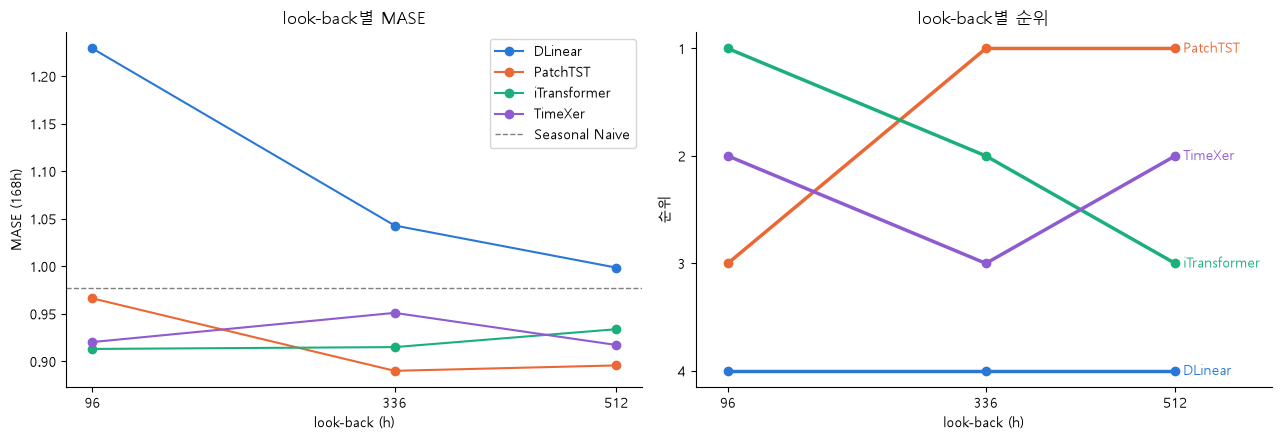

In [3]:
lb = pd.DataFrame({L: pick(seq_len=L, horizon=168)["MASE"] for L in [96, 336, 512]}).T.reindex(columns=MODELS)
lb.index.name = "look-back"
rank = lb.rank(axis=1).astype(int)

def rank_table(df, ref):
    order = df.apply(lambda r: list(r.sort_values().index), axis=1)
    t = pd.DataFrame(order.tolist(), index=df.index, columns=["1위", "2위", "3위", "4위"])
    t["1위 MASE"] = df.min(axis=1)
    r = df.rank(axis=1).astype(int)
    t[f"{ref} 대비 순위 변화"] = [", ".join(f"{m} {r.loc[ref, m]}→{r.loc[i, m]}" for m in MODELS
                                       if r.loc[i, m] != r.loc[ref, m]) or "없음" for i in df.index]
    return t

lb_rank = rank_table(lb, 336)
lb.to_csv(OUT / "lookback_mase.csv", encoding="utf-8")
lb_rank.to_csv(OUT / "lookback_rank.csv", encoding="utf-8")
print(lb.round(4).to_string())
print()
print(lb_rank.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for m in MODELS:
    axes[0].plot(lb.index, lb[m], "o-", color=COLORS[m], label=m)
    axes[1].plot(rank.index, rank[m], "o-", color=COLORS[m], lw=2.5)
    axes[1].annotate(m, (rank.index[-1], rank[m].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                     va="center", color=COLORS[m])
axes[0].axhline(NAIVE[168], color="gray", ls="--", lw=1, label="Seasonal Naive")
axes[0].set(xlabel="look-back (h)", ylabel="MASE (168h)", title="look-back별 MASE", xticks=lb.index)
axes[0].legend()
axes[1].set(xlabel="look-back (h)", ylabel="순위", title="look-back별 순위", xticks=rank.index, yticks=[1, 2, 3, 4])
axes[1].invert_yaxis()
axes[1].set_xlim(lb.index[0] - 30, lb.index[-1] + 90)
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "lookback_sensitivity.png", dpi=110)
plt.show()

## 과제 8-3b. 평가 층 — 하네스 설계 2종 순위표 (look-back 336 · 168h · 8주마다 재학습)

In [4]:
hz = pd.DataFrame({"2주차 설계 (expanding)": pick(seq_len=336, horizon=168, refit_hours=REFIT)["MASE"],
                   "반대 설계 (sliding)": pick(seq_len=336, horizon=168, refit_hours=REFIT, train_mode="sliding")["MASE"]}
                  ).T.reindex(columns=MODELS)
harness_table = rank_table(hz, "2주차 설계 (expanding)").rename(columns={"1위 MASE": "1위의 MASE"})
harness_table.to_csv(OUT / "harness_rank.csv", encoding="utf-8")
print(harness_table.to_string())
print()
delta = pd.DataFrame({"expanding": hz.iloc[0], "sliding": hz.iloc[1]})
delta["변화(%)"] = (delta["sliding"] / delta["expanding"] - 1) * 100
print(delta.round(4).to_string())

# 인자가 실제로 적용됐는지 — sliding 은 학습 행 수 8760 고정, expanding 은 재학습마다 증가
chk = fits.merge(runs[["task", "train_mode"]], left_on="run", right_index=True)
print()
print(chk[chk["task"] == "8-3b"].groupby("train_mode")["학습 행 수"].agg(["min", "max", "count"]).to_string())

                          1위       2위            3위       4위  1위의 MASE 2주차 설계 (expanding) 대비 순위 변화
2주차 설계 (expanding)  PatchTST  TimeXer  iTransformer  DLinear  0.888516                          없음
반대 설계 (sliding)     PatchTST  TimeXer  iTransformer  DLinear  0.920693                          없음

              expanding  sliding   변화(%)
model                                   
DLinear          1.0250   1.0480  2.2519
PatchTST         0.8885   0.9207  3.6215
iTransformer     0.9152   0.9761  6.6494
TimeXer          0.9127   0.9358  2.5320

             min    max  count
train_mode                    
expanding   8808  16872     28
sliding     8760   8760     28


### 두 층(+ seed)의 변동 크기 비교

In [5]:
ref_once = lb.loc[336]
knobs = [("모델 층: look-back 96", ref_once, lb.loc[96]),
         ("모델 층: look-back 512", ref_once, lb.loc[512]),
         ("평가 층: sliding", hz.iloc[0], hz.iloc[1])]
seeds = sorted(s for s in runs["seed"].unique() if s != SEED)
knobs += [(f"참고: seed {s}", ref_once, pick(seq_len=336, horizon=168, seed=s)["MASE"].reindex(MODELS)) for s in seeds]

cmp = pd.DataFrame([{"손잡이": k,
                     "순위 바뀐 모델 수": int((v.rank() != ref.rank()).sum()),
                     "1위 바뀜": v.idxmin() != ref.idxmin(),
                     "Kendall τ (1 = 순위 동일)": kendalltau(ref, v).statistic,
                     "평균 |ΔMASE| (%)": ((v - ref).abs() / ref * 100).mean(),
                     "최대 |ΔMASE| (%)": ((v - ref).abs() / ref * 100).max()} for k, ref, v in knobs])
cmp.to_csv(OUT / "sensitivity_comparison.csv", index=False, encoding="utf-8")
print(cmp.round(3).to_string(index=False))

                손잡이  순위 바뀐 모델 수  1위 바뀜  Kendall τ (1 = 순위 동일)  평균 |ΔMASE| (%)  최대 |ΔMASE| (%)
 모델 층: look-back 96           3   True                  0.333           7.466          17.859
모델 층: look-back 512           2  False                  0.667           2.624           4.247
      평가 층: sliding           0  False                  1.000           3.764           6.649
         참고: seed 0           2  False                  0.667           1.809           3.890
         참고: seed 1           0  False                  1.000           1.422           3.685


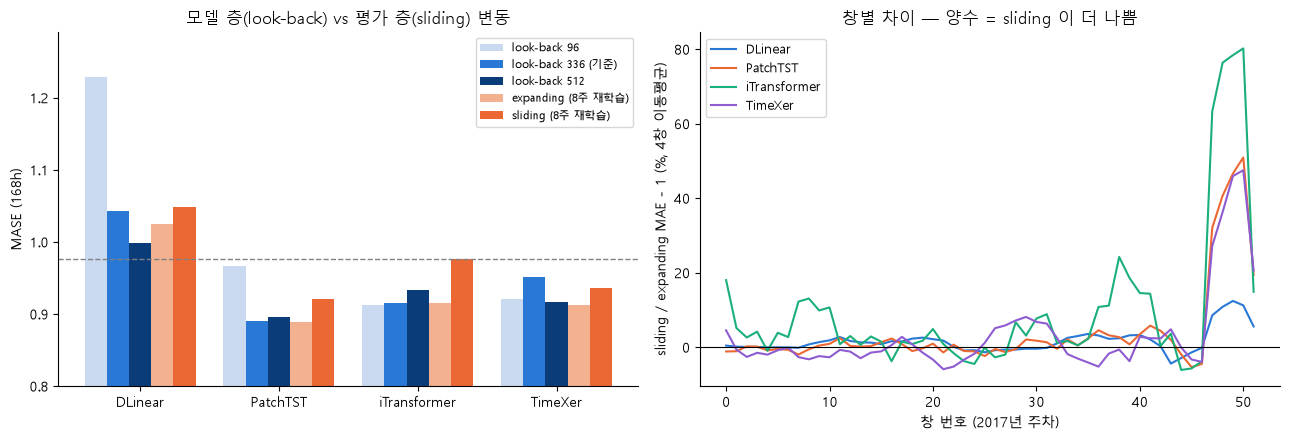

In [6]:
# 창별 비교: sliding 과 expanding 의 학습 데이터 차이는 뒤쪽 창으로 갈수록 커짐 (앞쪽 창은 둘 다 약 1년)
def window_mae(r):
    return preds[r].assign(ae=lambda d: (d["y_true"] - d["y_pred"]).abs()).groupby("window")["ae"].mean()

exp_r = pick(seq_len=336, horizon=168, refit_hours=REFIT)["run"]
sld_r = pick(seq_len=336, horizon=168, refit_hours=REFIT, train_mode="sliding")["run"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax, x, w = axes[0], np.arange(len(MODELS)), 0.16
settings = [("look-back 96", lb.loc[96], "#c9daf0"), ("look-back 336 (기준)", lb.loc[336], "#2a78d6"),
            ("look-back 512", lb.loc[512], "#0b3c7a"), ("expanding (8주 재학습)", hz.iloc[0], "#f3b18f"),
            ("sliding (8주 재학습)", hz.iloc[1], "#eb6834")]
for i, (label, v, c) in enumerate(settings):
    ax.bar(x + (i - 2) * w, v.reindex(MODELS), width=w, color=c, label=label)
ax.axhline(NAIVE[168], color="gray", ls="--", lw=1)
ax.set_xticks(x, MODELS)
ax.set_ylabel("MASE (168h)")
ax.set_ylim(0.8, None)
ax.set_title("모델 층(look-back) vs 평가 층(sliding) 변동")
ax.legend(fontsize=8)
ax = axes[1]
for m in MODELS:
    diff = (window_mae(sld_r[m]) / window_mae(exp_r[m]) - 1) * 100
    ax.plot(diff.index, diff.rolling(4, min_periods=1).mean(), color=COLORS[m], label=m)
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="창 번호 (2017년 주차)", ylabel="sliding / expanding MAE - 1 (%, 4창 이동평균)",
       title="창별 차이 — 양수 = sliding 이 더 나쁨")
ax.legend(fontsize=9)
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "harness_sensitivity.png", dpi=110)
plt.show()

## seed 편차 — 순위 차이가 seed 노이즈보다 큰가 (look-back 336 · 168h · 1회 학습)

                0       1       2021
model                               
DLinear       1.0399  1.0427  1.0429
PatchTST      0.9004  0.8962  0.8901
iTransformer  0.9323  0.9487  0.9150
TimeXer       0.9140  0.9632  0.9510

              seed 평균  seed 표준편차  seed 범위(최대-최소)  look-back 96~512 범위  |sliding - expanding|  sliding 차이 / seed 표준편차
model                                                                                                               
DLinear        1.0418     0.0017          0.0031               0.2306                 0.0231                 13.6132
PatchTST       0.8956     0.0052          0.0103               0.0762                 0.0322                  6.1818
iTransformer   0.9320     0.0169          0.0337               0.0208                 0.0609                  3.6095
TimeXer        0.9428     0.0256          0.0492               0.0338                 0.0231                  0.9022

seed 별 순위:
model  DLinear  PatchTST  iTransformer  TimeXer
0            4 

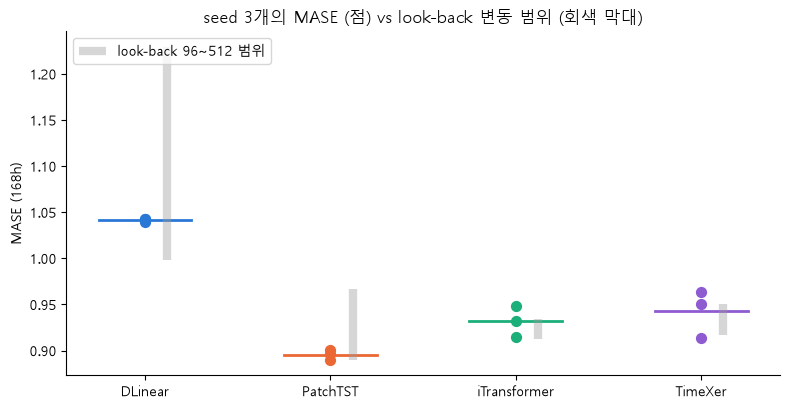

In [7]:
sv = pd.DataFrame({s: pick(seq_len=336, horizon=168, seed=s)["MASE"] for s in sorted(runs["seed"].unique())}).reindex(MODELS)
seed_rank = sv.T.rank(axis=1).astype(int)
summary = pd.DataFrame({"seed 평균": sv.mean(axis=1), "seed 표준편차": sv.std(axis=1),
                        "seed 범위(최대-최소)": sv.max(axis=1) - sv.min(axis=1),
                        "look-back 96~512 범위": lb.max() - lb.min(),
                        "|sliding - expanding|": (hz.iloc[1] - hz.iloc[0]).abs()})
summary["sliding 차이 / seed 표준편차"] = summary["|sliding - expanding|"] / summary["seed 표준편차"]
pd.concat([sv, summary], axis=1).to_csv(OUT / "seed_variance.csv", encoding="utf-8")
print(sv.round(4).to_string())
print()
print(summary.round(4).to_string())
print()
print("seed 별 순위:")
print(seed_rank.to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
for i, m in enumerate(MODELS):
    ax.scatter(np.full(len(sv.columns), i), sv.loc[m], color=COLORS[m], s=50, zorder=3)
    ax.plot([i - 0.25, i + 0.25], [sv.loc[m].mean()] * 2, color=COLORS[m], lw=2)
    ax.vlines(i + 0.12, lb[m].min(), lb[m].max(), color="#999999", lw=6, alpha=0.4,
              label="look-back 96~512 범위" if i == 0 else None)
ax.set_xticks(range(len(MODELS)), MODELS)
ax.set_ylabel("MASE (168h)")
ax.set_title("seed 3개의 MASE (점) vs look-back 변동 범위 (회색 막대)")
ax.legend(loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "seed_variance.png", dpi=110)
plt.show()

## 과제 8-4. TimeXer 외기온 공변량 vs 5주차 Chronos-2 (건물별 · look-back 336 · 1회 학습)

horizon                 24       168
TimeXer 전력만          0.5963   0.8816
TimeXer + 외기온        0.6205   0.8811
TimeXer 개선율(%)      -4.0553   0.0563
개선 건물 수                4/17    10/17
Wilcoxon p (건물 짝)    0.1089   0.9632
Chronos-2 zero-shot  0.3837     0.81
Chronos-2 + 외기온      0.3545   0.6969
Chronos-2 개선율(%)     7.5998  13.9696


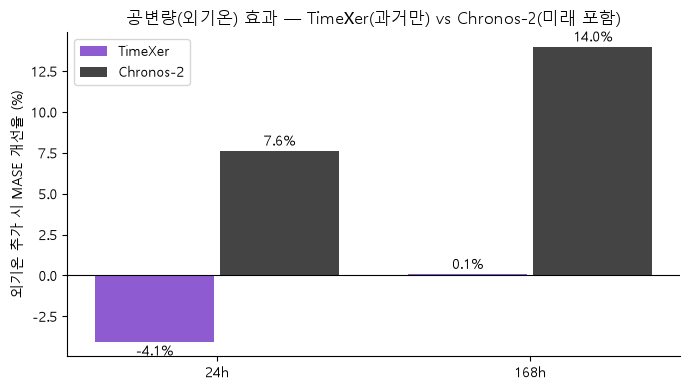

In [8]:
chronos_gain = pd.read_csv(ROOT / "results/wk5/covariate_gain.csv").set_index("horizon")
rows = []
for h in [24, 168]:
    a, b = (pb.loc[pick(model="TimeXer", seq_len=336, horizon=h, mode=md)["run"].item()] for md in ["S", "MS"])
    rows.append({"horizon": h, "TimeXer 전력만": a.mean(), "TimeXer + 외기온": b.mean(),
                 "TimeXer 개선율(%)": (a.mean() - b.mean()) / a.mean() * 100,
                 "개선 건물 수": f"{(b < a).sum()}/{len(a)}", "Wilcoxon p (건물 짝)": wilcoxon(a, b).pvalue,
                 "Chronos-2 zero-shot": chronos_gain.loc[h, "Chronos-2 zero-shot"],
                 "Chronos-2 + 외기온": chronos_gain.loc[h, "Chronos-2 + 외기온"],
                 "Chronos-2 개선율(%)": chronos_gain.loc[h, "개선율(%)"]})
cov = pd.DataFrame(rows).set_index("horizon")
cov.to_csv(OUT / "timexer_covariate.csv", encoding="utf-8")
print(cov.round(4).T.to_string())

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2)
for off, col, c in [(-0.2, "TimeXer 개선율(%)", COLORS["TimeXer"]), (0.2, "Chronos-2 개선율(%)", "#444444")]:
    bars = ax.bar(x + off, cov[col], width=0.38, color=c, label=col.replace(" 개선율(%)", ""))
    ax.bar_label(bars, fmt="%.1f%%", padding=2)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x, [f"{h}h" for h in cov.index])
ax.set_ylabel("외기온 추가 시 MASE 개선율 (%)")
ax.set_title("공변량(외기온) 효과 — TimeXer(과거만) vs Chronos-2(미래 포함)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "covariate_comparison.png", dpi=110)
plt.show()

## horizon(24h ↔ 168h)별 순위 (look-back 336 · 1회 학습)

In [9]:
hr = pd.DataFrame({f"{h}h": pick(seq_len=336, horizon=h)["MASE"] for h in [24, 168]}).T.reindex(columns=MODELS)
hr_rank = rank_table(hr, "168h")
hr.to_csv(OUT / "horizon_mase.csv", encoding="utf-8")
hr_rank.to_csv(OUT / "horizon_rank.csv", encoding="utf-8")
print(hr.round(4).to_string())
print()
print(hr_rank.to_string())

model  DLinear  PatchTST  iTransformer  TimeXer
24h     0.8484    0.6469        0.6134   0.6124
168h    1.0429    0.8901        0.9150   0.9510

            1위            2위        3위       4위   1위 MASE              168h 대비 순위 변화
24h    TimeXer  iTransformer  PatchTST  DLinear  0.612364  PatchTST 1→3, TimeXer 3→1
168h  PatchTST  iTransformer   TimeXer  DLinear  0.890067                         없음


## 건물 17개를 한 입력에 섞기(M) vs 건물별(S) — TimeXer (look-back 336 · 1회 학습)

In [10]:
cm = pd.DataFrame({h: {"TimeXer 17채널 (M)": pick(model="TimeXer", seq_len=336, horizon=h)["MASE"].item(),
                        "TimeXer 건물별 (S)": pick(model="TimeXer", seq_len=336, horizon=h, mode="S")["MASE"].item()}
                   for h in [24, 168]})
cm.loc["건물별 개선율(%)"] = (cm.iloc[0] - cm.iloc[1]) / cm.iloc[0] * 100
cm.to_csv(OUT / "channel_mixing.csv", encoding="utf-8")
print(cm.round(4).to_string())
for h in [24, 168]:
    r_m, r_s = (pick(model="TimeXer", seq_len=336, horizon=h, mode=md)["run"].item() for md in ["M", "S"])
    print(f"{h}h 건물별(S)이 더 좋은 건물: {(pb.loc[r_s] < pb.loc[r_m]).sum()}/{pb.shape[1]}")

                     24      168
TimeXer 17채널 (M)  0.6124  0.9510
TimeXer 건물별 (S)   0.5963  0.8816
건물별 개선율(%)        2.6161  7.3037
24h 건물별(S)이 더 좋은 건물: 10/17
168h 건물별(S)이 더 좋은 건물: 16/17


## 과제 8-5. 하네스 통합 — tidy 저장 + 누적 비교표 (LightGBM · Chronos-2 · TTM · LoRA · 딥러닝)

In [11]:
TIDY = OUT / "tidy"
TIDY.mkdir(exist_ok=True)
dl = {h: pick(seq_len=336, horizon=h).reindex(MODELS) for h in [24, 168]}
for h in [24, 168]:
    for m in MODELS:
        preds[dl[h].loc[m, "run"]].to_csv(TIDY / f"{m}_{h}h.csv", index=False, encoding="utf-8")  # 2주차 하네스 tidy 형식 그대로

lora = pd.read_csv(ROOT / "results/wk7/lora_summary.csv").set_index("horizon")["LoRA MASE (seed 평균)"]
lora_cost = pd.read_csv(ROOT / "results/wk7/lora_cost.csv").set_index("horizon")["학습 시간(s)"]
cum = wk6.copy()
cum["학습 1회(s)"] = bench6["학습 시간(s)"]
cum["학습 장치"] = np.where(cum.index.str.startswith("LightGBM"), "노트북 CPU", "— (학습 없음)")
cum.loc["Chronos-2 LoRA (7주차)"] = [lora[24], lora[168], lora_cost.mean(), "GPU"]
for m in MODELS:
    cum.loc[f"{m} (look-back 336)"] = [dl[24].loc[m, "MASE"], dl[168].loc[m, "MASE"], dl[168].loc[m, "학습 1회 평균(s)"], "GPU"]
for md, name in [("S", "TimeXer 건물별 (전력만)"), ("MS", "TimeXer 건물별 + 외기온")]:
    p = {h: pick(model="TimeXer", seq_len=336, horizon=h, mode=md) for h in [24, 168]}
    cum.loc[name] = [p[24]["MASE"].item(), p[168]["MASE"].item(), p[168]["학습 1회 평균(s)"].item(), "GPU"]
for h in [24, 168]:
    cum[f"Naive 대비 {h}h(%)"] = vs_naive(cum[f"MASE({h}h)"].astype(float), h)
cum = cum[["MASE(24h)", "Naive 대비 24h(%)", "MASE(168h)", "Naive 대비 168h(%)", "학습 1회(s)", "학습 장치"]]
cum.to_csv(OUT / "cumulative_table.csv", encoding="utf-8")
print(cum.round(4).to_string())

                              MASE(24h)  Naive 대비 24h(%)  MASE(168h)  Naive 대비 168h(%)  학습 1회(s)      학습 장치
Seasonal Naive                   0.9673           0.0000      0.9767            0.0000       NaN  — (학습 없음)
LightGBM (local)                 0.5501         -43.1268      0.9298           -4.8052    4.2931    노트북 CPU
LightGBM (global)                0.6211         -35.7857      0.9955            1.9222    5.9697    노트북 CPU
Chronos-2                        0.3837         -60.3320      0.8100          -17.0667       NaN  — (학습 없음)
Chronos-2 + 공변량                  0.3545         -63.3467      0.6969          -28.6522       NaN  — (학습 없음)
TTM (ctx=512)                    0.7447         -23.0134      1.0899           11.5834       NaN  — (학습 없음)
TTM (ctx=1024)                   0.7933         -17.9869      0.9898            1.3375       NaN  — (학습 없음)
Chronos-2 LoRA (7주차)             0.3904         -59.6431      0.7908          -19.0321  268.8636        GPU
DLinear (look-back 336)     

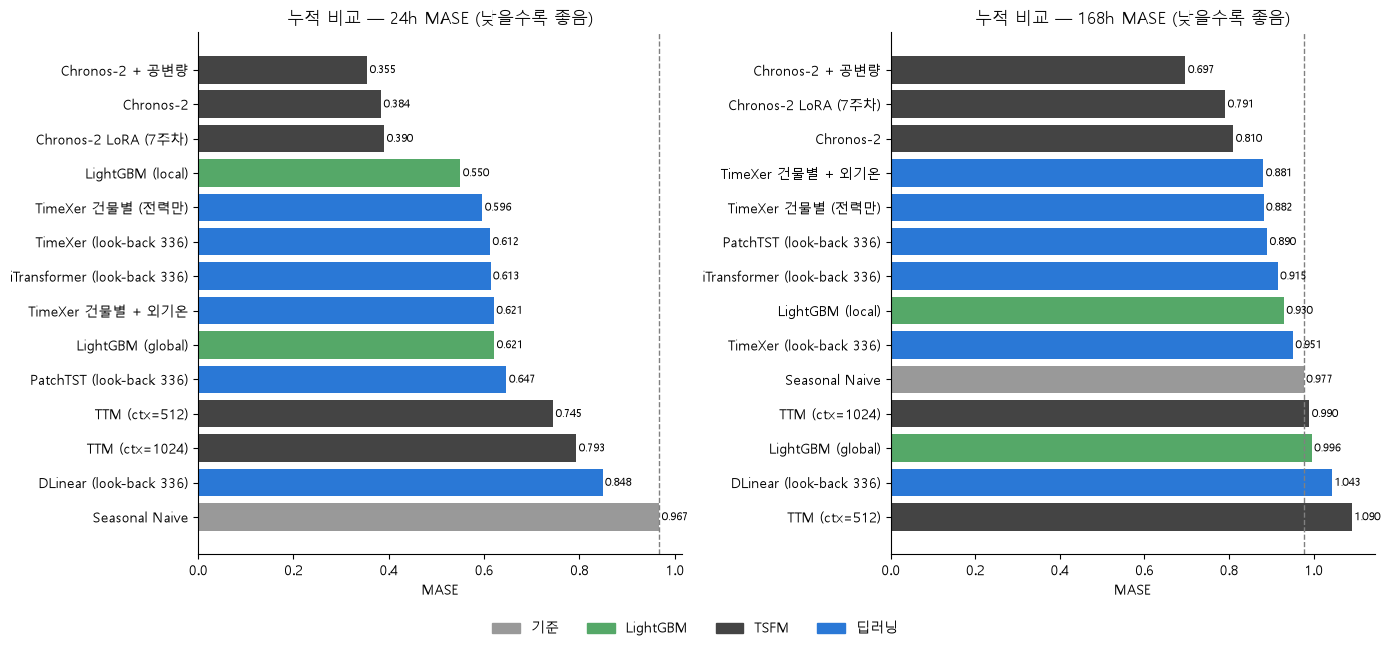

In [12]:
family = lambda name: ("딥러닝" if any(name.startswith(m) for m in MODELS) else "TSFM" if name.startswith(("Chronos", "TTM"))
                       else "LightGBM" if name.startswith("LightGBM") else "기준")
FAM = {"기준": "#999999", "LightGBM": "#55A868", "TSFM": "#444444", "딥러닝": "#2a78d6"}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, h in zip(axes, [24, 168]):
    s = cum[f"MASE({h}h)"].astype(float).sort_values(ascending=False)
    bars = ax.barh(s.index, s, color=[FAM[family(n)] for n in s.index])
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8)
    ax.axvline(NAIVE[h], color="gray", ls="--", lw=1)
    ax.set_title(f"누적 비교 — {h}h MASE (낮을수록 좋음)")
    ax.set_xlabel("MASE")
    ax.spines[["top", "right"]].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAM.values()]
fig.legend(handles, FAM.keys(), loc="lower center", ncol=len(FAM), frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig(OUT / "cumulative_mase.png", dpi=110)
plt.show()